# Machine-Learning Return Prediction with SQL: Japanese Stocks
**Author:** Silam Shrestha

**Question:** Can a model that combines several signals predict next month's stock returns better than any single signal, when tested honestly on data it has never seen?

**What this project shows**
- **SQL:** prices are stored in a database and features are built with SQL window functions.
- **Predictive models:** a linear model (Ridge regression) and a non-linear model (Gradient Boosting).
- **Walk-forward validation:** train only on the past, predict the next year, then move forward one year and repeat. This is how systematic funds test models.
- **Information Coefficient (IC):** the standard way quant researchers measure how well a prediction ranks stocks.
- **Portfolio test:** turn predictions into a long-short portfolio, after trading costs, and compare with single signals.

## Step 1. Tools

In [1]:
!pip install yfinance -q
import sqlite3
import numpy as np, pandas as pd, matplotlib.pyplot as plt, yfinance as yf
from sklearn.linear_model import Ridge
from sklearn.ensemble import GradientBoostingRegressor
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

## Step 2. Settings and data
Same 30 large Japanese companies as Project 1, but starting in **2010** so the models have more history to learn from.

In [2]:
TICKERS = [
    "7203.T", "6758.T", "9984.T", "8306.T", "6861.T", "9432.T", "8035.T", "6098.T",
    "4063.T", "9983.T", "7974.T", "8316.T", "6501.T", "4502.T", "8058.T", "8001.T",
    "6367.T", "7267.T", "4568.T", "6902.T", "9433.T", "8766.T", "6954.T", "4519.T",
    "6594.T", "7741.T", "6981.T", "8411.T", "2914.T", "4661.T",
]
START, END = "2010-01-01", "2025-12-31"
FIRST_TEST_YEAR, LAST_TEST_YEAR = 2016, 2025
COST = 0.0010

raw = yf.download(TICKERS, start=START, end=END, auto_adjust=True, progress=False)
daily = raw["Close"].dropna(how="all")
if daily.empty:
    raise RuntimeError("No data downloaded. Check internet and run again.")
monthly = daily.resample("ME").last()

# Data check: flag impossible monthly moves (for example unadjusted splits)
mret = monthly.pct_change()
bad = mret.stack()[mret.stack().abs() > 0.6]
print("Suspicious monthly moves (>60%):", len(bad))
print(bad.head(10))
print(monthly.shape)

Suspicious monthly moves (>60%): 0
Series([], dtype: float64)
(192, 30)


## Step 3. Store the data in a SQL database
We put monthly prices in a **SQLite** database (a real SQL database that runs inside Python), in "long" format: one row per (date, ticker).

In [3]:
con = sqlite3.connect(":memory:")
long = monthly.stack().rename("close").reset_index()
long.columns = ["date", "ticker", "close"]
long["date"] = long["date"].dt.strftime("%Y-%m-%d")
long.to_sql("prices", con, index=False)

pd.read_sql("""
    SELECT ticker, COUNT(*) AS months, MIN(date) AS first_month, MAX(date) AS last_month
    FROM prices
    GROUP BY ticker
    ORDER BY months
    LIMIT 5
""", con)

,ticker,months,first_month,last_month
0,6098.T,135,2014-10-31,2025-12-31
1,2914.T,192,2010-01-31,2025-12-31
2,4063.T,192,2010-01-31,2025-12-31
3,4502.T,192,2010-01-31,2025-12-31
4,4519.T,192,2010-01-31,2025-12-31


## Step 4. Build features with SQL window functions
`LAG(close, k)` gives the price *k* months earlier for the same stock; `LEAD(close, 1)` gives next month's price (used **only for the target**).

| Feature | Meaning |
|---|---|
| `ret_1m` | Last month's return (reversal signal) |
| `mom_3m` | Return over the last 3 months |
| `mom_12_1` | Return from 12 months ago to 1 month ago (momentum) |
| `next_ret` | **Target:** next month's return |

In [4]:
query = """
SELECT date, ticker, close,
       close / LAG(close, 1) OVER w - 1                 AS ret_1m,
       close / LAG(close, 3) OVER w - 1                 AS mom_3m,
       LAG(close, 1) OVER w / LAG(close, 12) OVER w - 1 AS mom_12_1,
       LEAD(close, 1) OVER w / close - 1                AS next_ret
FROM prices
WINDOW w AS (PARTITION BY ticker ORDER BY date)
ORDER BY date, ticker
"""
df = pd.read_sql(query, con, parse_dates=["date"])
df["vol_6m"] = df.groupby("ticker")["ret_1m"].transform(lambda r: r.rolling(6).std())
df.tail()

,date,ticker,close,ret_1m,mom_3m,mom_12_1,next_ret,vol_6m
5698,2025-12-31,8766.T,295.0677,0.0559,-0.0721,-0.0070,NaN,0.0517
5699,2025-12-31,9432.T,152.6750,0.0122,0.0194,0.0205,NaN,0.0160
5700,2025-12-31,9433.T,"2,631.1191",0.0071,0.1474,0.1015,NaN,0.0501
5701,2025-12-31,9983.T,"56,250.9805",-0.0035,0.2642,0.0731,NaN,0.1154
5702,2025-12-31,9984.T,"4,389.9971",0.0461,-0.0581,0.8390,NaN,0.2923


## Step 5. Prepare features and target
- **Rank features within each month** (from −0.5 to +0.5). This removes the effect of the whole market going up or down and stops extreme values dominating.
- **Target = next month's return minus that month's average.** We want to predict which stocks do *better than others*, not whether the market rises.

In [5]:
FEATURES = ["ret_1m", "mom_3m", "mom_12_1", "vol_6m"]
for f in FEATURES:
    df[f + "_r"] = df.groupby("date")[f].rank(pct=True) - 0.5
X_COLS = [f + "_r" for f in FEATURES]
df["target"] = df["next_ret"] - df.groupby("date")["next_ret"].transform("mean")
data = df.dropna(subset=X_COLS + ["target"]).copy()
print(len(data), "stock-months from", data.date.min().date(), "to", data.date.max().date())

5313 stock-months from 2011-01-31 to 2025-11-30


## Step 6. Walk-forward validation
For each test year (2016 to 2025):
1. **Train** on every month **before** that year.
2. **Predict** every month of that year.
3. Move forward one year and repeat.

The model never sees the future. The last training row (December) uses January's return as its target, which is already known when we make January's prediction at the end of January.

In [6]:
MODELS = {
    "Ridge": lambda: Ridge(alpha=1.0),
    "GradientBoosting": lambda: GradientBoostingRegressor(n_estimators=150, max_depth=2, learning_rate=0.05,
                                                          subsample=0.8, random_state=0),
}
preds = []
for year in range(FIRST_TEST_YEAR, LAST_TEST_YEAR + 1):
    train = data[data.date < f"{year}-01-01"]
    test = data[data.date.dt.year == year].copy()
    if test.empty:
        continue
    for name, make in MODELS.items():
        model = make().fit(train[X_COLS], train["target"])
        test["pred_" + name] = model.predict(test[X_COLS])
    preds.append(test)
pred = pd.concat(preds)
print("Predictions:", len(pred), "rows,", pred.date.dt.year.min(), "to", pred.date.dt.year.max())

Predictions: 3570 rows, 2016 to 2025


## Step 7. Information Coefficient (IC)
Each month, IC = **rank correlation** between our predictions and the actual next-month returns.
- IC > 0 means the model ranks stocks in the right order more often than not.
- In real quant research, a **stable IC of 0.02 to 0.05 is already useful**, because it is applied to many stocks over many months.
- **IC t-stat** = mean IC ÷ (standard deviation ÷ √months). Above about 2 suggests it is not luck.

We also compute the IC of each single signal for comparison.

In [7]:
def ic_series(frame, score_col):
    return frame.groupby("date").apply(lambda g: g[score_col].corr(g["next_ret"], method="spearman"), include_groups=False)

score_cols = {"Ridge": "pred_Ridge", "GradientBoosting": "pred_GradientBoosting",
              "Momentum only": "mom_12_1_r", "Reversal only (−ret_1m)": None}
pred["rev_score"] = -pred["ret_1m_r"]
score_cols["Reversal only (−ret_1m)"] = "rev_score"

ic_table, ics = {}, {}
for name, col in score_cols.items():
    s = ic_series(pred, col).dropna()
    ics[name] = s
    ic_table[name] = {"Mean IC": s.mean(), "IC std": s.std(), "IC t-stat": s.mean() / (s.std() / np.sqrt(len(s))),
                      "% months IC > 0": (s > 0).mean(), "Months": len(s)}
pd.DataFrame(ic_table).T

,Mean IC,IC std,IC t-stat,% months IC > 0,Months
Ridge,0.0236,0.2588,0.9945,0.5210,119.0000
GradientBoosting,-0.0223,0.1967,-1.2392,0.4958,119.0000
Momentum only,0.0143,0.2915,0.5368,0.4958,119.0000
Reversal only (−ret_1m),0.0350,0.2699,1.4150,0.5462,119.0000


## Step 8. Turn predictions into a long-short portfolio
Same method as Project 1: each month buy the top third of predicted stocks, sell the bottom third, hold one month, subtract 0.10% cost per unit traded.

In [8]:
def long_short(signal, next_ret, cost=COST, frac=1/3, min_stocks=9):
    weights = pd.DataFrame(0.0, index=signal.index, columns=signal.columns)
    for date in signal.index:
        s = signal.loc[date]
        s = s[s.notna() & next_ret.loc[date].notna()]
        if len(s) < min_stocks:
            continue
        n = int(len(s) * frac)
        ranked = s.sort_values()
        weights.loc[date, ranked.index[-n:]] = 1.0 / n
        weights.loc[date, ranked.index[:n]] = -1.0 / n
    weights = weights[weights.abs().sum(axis=1) > 0]
    gross = (weights * next_ret.loc[weights.index]).sum(axis=1)
    turnover = weights.diff().abs().sum(axis=1)
    turnover.iloc[0] = weights.iloc[0].abs().sum()
    return pd.DataFrame({"gross": gross, "net": gross - turnover * cost, "turnover": turnover})

def perf(r):
    r = r.dropna()
    cum = (1 + r).cumprod()
    return pd.Series({"Annual return": r.mean() * 12, "Annual volatility": r.std() * np.sqrt(12),
                      "Sharpe": r.mean() / r.std() * np.sqrt(12), "Max drawdown": (cum / cum.cummax() - 1).min(),
                      "t-stat": r.mean() / (r.std() / np.sqrt(len(r)))})

next_ret_w = pred.pivot(index="date", columns="ticker", values="next_ret")
port, rows = {}, {}
for name, col in score_cols.items():
    sig = pred.pivot(index="date", columns="ticker", values=col)
    port[name] = long_short(sig, next_ret_w)
    rows[name] = pd.concat([perf(port[name]["net"]), pd.Series({"Avg turnover": port[name]["turnover"].mean()})])
pd.DataFrame(rows).T

,Annual return,Annual volatility,Sharpe,Max drawdown,t-stat,Avg turnover
Ridge,0.0270,0.1388,0.1943,-0.4466,0.6120,2.4689
GradientBoosting,-0.0845,0.1138,-0.7429,-0.6206,-2.3394,2.3143
Momentum only,0.0129,0.1500,0.0862,-0.2313,0.2714,0.7613
Reversal only (−ret_1m),0.0453,0.1474,0.3073,-0.3987,0.9678,2.7059


## Step 9. Plot cumulative performance (after costs)

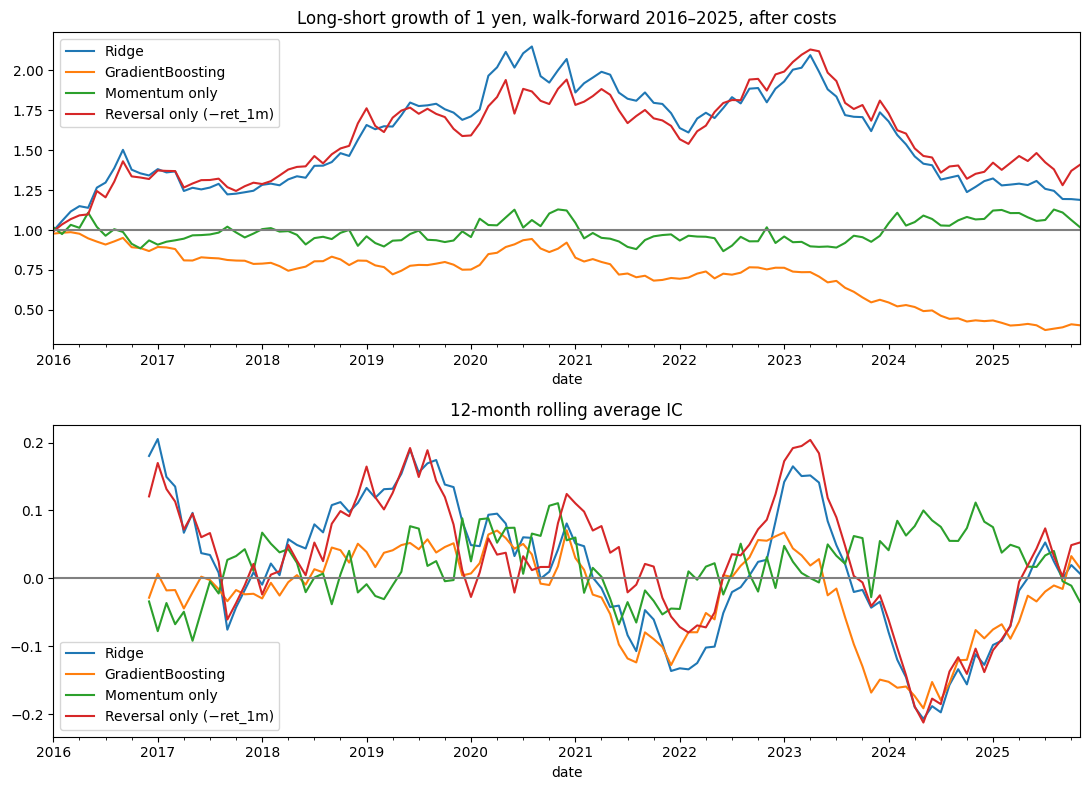

In [9]:
fig, ax = plt.subplots(2, 1, figsize=(11, 8))
for name, res in port.items():
    (1 + res["net"]).cumprod().plot(ax=ax[0], label=name)
ax[0].axhline(1, color="grey"); ax[0].legend(); ax[0].set_title("Long-short growth of 1 yen, walk-forward 2016–2025, after costs")
for name, s in ics.items():
    s.rolling(12).mean().plot(ax=ax[1], label=name)
ax[1].axhline(0, color="grey"); ax[1].legend(); ax[1].set_title("12-month rolling average IC")
plt.tight_layout(); plt.show()

## Step 10. What did the models learn?
- **Ridge coefficients:** positive means a higher rank predicts higher next-month return.
- **Gradient Boosting importance:** how much each feature was used.

Both are fitted on all data before 2025, the last training set.

In [10]:
train = data[data.date < f"{LAST_TEST_YEAR}-01-01"]
ridge = Ridge(alpha=1.0).fit(train[X_COLS], train["target"])
gb = MODELS["GradientBoosting"]().fit(train[X_COLS], train["target"])
pd.DataFrame({"Ridge coefficient": ridge.coef_, "GB importance": gb.feature_importances_}, index=FEATURES)

,Ridge coefficient,GB importance
ret_1m,-0.0103,0.3106
mom_3m,0.0030,0.2401
mom_12_1,0.0019,0.1827
vol_6m,0.0037,0.2665


## Step 11. Conclusions
1. **No model produced a statistically reliable edge.** Out of sample (2016–2025, 119 months), the best IC came from the simple reversal signal (mean IC 0.035, t = 1.42), followed by Ridge (0.024, t = 0.99). Neither reaches t = 2.
2. **Ridge roughly matched the best single signal but did not beat it.** After costs, Ridge had a Sharpe of 0.19, versus 0.31 for reversal alone and 0.09 for momentum alone. Its largest coefficient was on last month's return (negative), so it mostly learned the reversal effect, consistent with Project 1.
3. **Gradient Boosting overfit.** It had a negative IC (−0.022) and the worst portfolio (Sharpe −0.74, max drawdown −62%). With only about 3,500 noisy training rows and 4 features, the flexible model learned patterns that did not repeat. Its feature importance was spread across all four features, a typical sign of fitting noise rather than signal.
4. **Lesson:** with small, noisy financial data, a simple and well-understood model is safer than a complex one. More data (more stocks, more features) is needed before non-linear models can help.

**Limitations:** only 30 stocks and 4 simple price features; survivorship bias (today's large caps); simple costs; models were not tuned (to avoid overfitting through repeated testing); predictions refresh once a year.

**Next steps:** add more stocks and fundamental features (value, profitability), tune models with nested walk-forward validation, and neutralise sector exposure.